In [77]:
import logging
import os
import random
import shutil
import warnings
import yaml
import cv2
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub import hf_hub_download
from pathlib import Path
from PIL import Image
from ultralytics import YOLO

In [78]:
SMALL_DATASET_DIR = Path('smoke_yolo_dataset')
MICRO_DATASET_DIR = Path('smoke_yolo_dataset_micro')
CONF = 0.4
N_VISUAL_SAMPLES = 5
OUTPUT_DIR = Path('smoke_comparison_results')
OUTPUT_DIR.mkdir(exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

OWN_EXPERIMENTS = [
    {
        'name': 'YOLOv26m_smoke_micro',
        'experiment_dir': 'runs/detect/smoke_boxes_micro_m/smoking_yolo26m_micro',
        'dataset_path': MICRO_DATASET_DIR,
    },
    {
        'name': 'YOLOv26s_smoke_micro',
        'experiment_dir': 'runs/detect/smoke_boxes_micro_s/smoking_yolo26s_micro',
        'dataset_path': MICRO_DATASET_DIR,
    },
    {
        'name': 'YOLOv26s_smoke_small',
        'experiment_dir': 'runs/detect/smoke_boxes_small_s/smoking_yolo26s',
        'dataset_path': SMALL_DATASET_DIR,
    },
    {
        'name': 'YOLOv26m_smoke_small',
        'experiment_dir': 'runs/detect/smoke_boxes_small_m/smoking_yolo26m',
        'dataset_path': SMALL_DATASET_DIR,
    },
]

OPENSOURCE_MODELS = [
    {
        'name': 'TommyNgx_yolov10_fire_smoke',
        'hf_repo': 'TommyNgx/YOLOv10-Fire-and-Smoke-Detection',
        'hf_filename': 'best.pt',
        'smoking_class_names': ['smoke', 'Smoke'],
    },
    {
        'name': 'leeyunjai_yolo11s_fire_smoke',
        'hf_repo': 'leeyunjai/yolo11-firedetect',
        'hf_filename': 'firedetect-11s.pt',
        'smoking_class_names': ['smoke'],
    },
    {
        'name': 'leeyunjai_yolo11x_fire_smoke',
        'hf_repo': 'leeyunjai/yolo11-firedetect',
        'hf_filename': 'firedetect-11x.pt',
        'smoking_class_names': ['smoke'],
    },
]

Device: cuda


In [79]:
def evaluate_experiment(experiment_dir, dataset_path, conf=0.3, n_visual_samples=5, device=None):
    logging.getLogger('ultralytics').setLevel(logging.ERROR)
    warnings.filterwarnings('ignore')

    experiment_dir = Path(experiment_dir)
    dataset_path = Path(dataset_path)

    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'

    weights_dir = experiment_dir / 'weights'
    best_weights = weights_dir / 'best.pt'
    if not best_weights.exists():
        best_weights = weights_dir / 'last.pt'
    if not best_weights.exists():
        raise FileNotFoundError(f'No weights found in {weights_dir}')

    model = YOLO(str(best_weights))
    model.overrides['verbose'] = False

    data_yaml_path = dataset_path / 'data.yaml'
    if not data_yaml_path.exists():
        raise FileNotFoundError(f'data.yaml not found in {dataset_path}')

    print(f'Evaluating: {experiment_dir.name}')
    print(f'Weights: {best_weights}')
    print(f'Dataset: {dataset_path}')

    results_png = experiment_dir / 'results.png'
    if results_png.exists():
        fig, ax = plt.subplots(1, 1, figsize=(14, 6))
        img = Image.open(results_png)
        ax.imshow(img)
        ax.axis('off')
        ax.set_title('Training Results', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f'{experiment_dir.name}_training_curves.png', dpi=150, bbox_inches='tight')
        plt.show()

    summary = {}

    for eval_split in ['val', 'test']:
        split_images_dir = dataset_path / eval_split / 'images'
        if not split_images_dir.exists():
            print(f"Split '{eval_split}' not found, skipping.")
            continue

        metrics = model.val(
            data=str(data_yaml_path),
            split=eval_split,
            device=device,
            plots=False,
            verbose=False,
        )

        precision = float(metrics.box.p[0])
        recall = float(metrics.box.r[0])
        map50 = float(metrics.box.map50)
        map5095 = float(metrics.box.map)
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

        print('=' * 50)
        print(f"Metrics on '{eval_split}':")
        print(f'  mAP50:     {map50:.4f}')
        print(f'  mAP50-95:  {map5095:.4f}')
        print(f'  Precision: {precision:.4f}')
        print(f'  Recall:    {recall:.4f}')
        print(f'  F1:        {f1:.4f}')
        print('=' * 50)

        summary[eval_split] = {
            'mAP50': map50,
            'mAP50-95': map5095,
            'precision': precision,
            'recall': recall,
            'f1': f1,
        }

    images_dir = dataset_path / 'test' / 'images'
    labels_dir = dataset_path / 'test' / 'labels'
    if not images_dir.exists():
        images_dir = dataset_path / 'val' / 'images'
        labels_dir = dataset_path / 'val' / 'labels'

    if images_dir.exists():
        all_images = list(images_dir.iterdir())
        sample_images = random.sample(all_images, min(n_visual_samples, len(all_images)))
        n_cols = len(sample_images)
        fig, axes = plt.subplots(1, n_cols, figsize=(5 * n_cols, 5))
        if n_cols == 1:
            axes = [axes]

        for idx, img_path in enumerate(sample_images):
            pred_results = model.predict(str(img_path), conf=conf, device=device, verbose=False)
            img_cv = cv2.imread(str(img_path))
            img_rgb = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)
            h, w = img_rgb.shape[:2]
            ax = axes[idx]
            ax.imshow(img_rgb)

            lbl_path = labels_dir / (img_path.stem + '.txt')
            if lbl_path.exists():
                with open(lbl_path, 'r') as f:
                    for line in f:
                        parts = line.strip().split()
                        if len(parts) >= 5:
                            _, x_center, y_center, bw, bh = map(float, parts[:5])
                            x_min = int((x_center - bw / 2) * w)
                            y_min = int((y_center - bh / 2) * h)
                            rect = patches.Rectangle(
                                (x_min, y_min), int(bw * w), int(bh * h),
                                linewidth=2, edgecolor='green', facecolor='none'
                            )
                            ax.add_patch(rect)

            if len(pred_results[0].boxes) > 0:
                boxes = pred_results[0].boxes.xyxy.cpu().numpy()
                scores = pred_results[0].boxes.conf.cpu().numpy()
                for box, score in zip(boxes, scores):
                    x1, y1, x2, y2 = box
                    rect = patches.Rectangle(
                        (x1, y1), x2 - x1, y2 - y1,
                        linewidth=2, edgecolor='red', facecolor='none', linestyle='--'
                    )
                    ax.add_patch(rect)
                    ax.text(x1, y1 - 5, f'{score:.2f}',
                            color='red', fontsize=9, weight='bold',
                            bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

            ax.set_title(f'{img_path.name}\nPred: {len(pred_results[0].boxes)}', fontsize=8)
            ax.axis('off')

        green_patch = patches.Patch(color='green', label='Ground Truth')
        red_patch = patches.Patch(color='red', label=f'Prediction (conf>{conf})')
        fig.legend(handles=[green_patch, red_patch], loc='upper center', ncol=2, fontsize=12)
        fig.suptitle(f'Visual predictions: {experiment_dir.name}', fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f'{experiment_dir.name}_visual.png', dpi=150, bbox_inches='tight')
        plt.show()

    return summary

In [80]:
def compute_iou(box_a, box_b):
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


def compute_metrics_custom(model, dataset_path, split, smoking_class_ids, conf=0.3, iou_thresh=0.5, device='cuda'):
    images_dir = dataset_path / split / 'images'
    labels_dir = dataset_path / split / 'labels'
    if not images_dir.exists():
        return None

    tp_list = []
    fp_list = []
    fn_list = []
    all_scores = []
    all_tp_flags = []

    for img_path in sorted(images_dir.iterdir()):
        if img_path.suffix.lower() not in {'.jpg', '.jpeg', '.png', '.bmp'}:
            continue

        lbl_path = labels_dir / (img_path.stem + '.txt')
        gt_boxes = []
        if lbl_path.exists():
            img_cv = cv2.imread(str(img_path))
            h, w = img_cv.shape[:2]
            with open(lbl_path, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        cls = int(float(parts[0]))
                        if cls == 0:
                            xc, yc, bw, bh = map(float, parts[1:5])
                            x1 = (xc - bw / 2) * w
                            y1 = (yc - bh / 2) * h
                            x2 = (xc + bw / 2) * w
                            y2 = (yc + bh / 2) * h
                            gt_boxes.append([x1, y1, x2, y2])

        results = model.predict(str(img_path), conf=conf, device=device, verbose=False)
        pred_boxes = []
        pred_scores = []
        if len(results[0].boxes) > 0:
            cls_ids = results[0].boxes.cls.cpu().numpy().astype(int)
            for i, cls_id in enumerate(cls_ids):
                if cls_id in smoking_class_ids:
                    box = results[0].boxes.xyxy[i].cpu().numpy()
                    score = float(results[0].boxes.conf[i].cpu())
                    pred_boxes.append(box)
                    pred_scores.append(score)

        matched_gt = set()
        for pred_box, score in sorted(zip(pred_boxes, pred_scores), key=lambda x: -x[1]):
            best_iou = 0
            best_gt_idx = -1
            for gt_idx, gt_box in enumerate(gt_boxes):
                if gt_idx in matched_gt:
                    continue
                iou = compute_iou(pred_box, gt_box)
                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = gt_idx

            if best_iou >= iou_thresh and best_gt_idx >= 0:
                tp_list.append(1)
                fp_list.append(0)
                matched_gt.add(best_gt_idx)
                all_tp_flags.append(1)
            else:
                tp_list.append(0)
                fp_list.append(1)
                all_tp_flags.append(0)
            all_scores.append(score)

        fn_list.append(len(gt_boxes) - len(matched_gt))

    tp = sum(tp_list)
    fp = sum(fp_list)
    fn = sum(fn_list)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

    if all_scores:
        pairs = sorted(zip(all_scores, all_tp_flags), key=lambda x: -x[0])
        cum_tp = 0
        cum_fp = 0
        precisions = []
        recalls = []
        total_gt = tp + fn
        for _, is_tp in pairs:
            if is_tp:
                cum_tp += 1
            else:
                cum_fp += 1
            p = cum_tp / (cum_tp + cum_fp)
            r = cum_tp / total_gt if total_gt > 0 else 0.0
            precisions.append(p)
            recalls.append(r)
        precisions = np.array(precisions)
        recalls = np.array(recalls)
        map50 = float(np.trapz(precisions, recalls)) if len(recalls) > 1 else 0.0
    else:
        map50 = 0.0

    return {'mAP50': map50, 'precision': precision, 'recall': recall, 'f1': f1}

In [81]:
def inspect_model_classes(cfg, probe_images, conf=0.1, device='cuda'):
    print(f"\n{'='*60}")
    print(f"Model: {cfg['name']}")

    model_path = hf_hub_download(repo_id=cfg['hf_repo'], filename=cfg['hf_filename'])
    model = YOLO(model_path)
    model.overrides['verbose'] = False

    if not probe_images:
        print('No probe images')
        return None, None

    n_cols = len(probe_images)
    fig, axes = plt.subplots(1, n_cols, figsize=(6 * n_cols, 6))
    if n_cols == 1:
        axes = [axes]

    all_results = []
    for img_path in probe_images:
        img_cv = cv2.imread(str(img_path))
        img_rgb = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)
        results = model.predict(str(img_path), conf=conf, device=device, verbose=False)
        all_results.append((img_path, img_rgb, results))

    names_str = ', '.join(f'{k}:{v}' for k, v in sorted(model.names.items()))
    print(f'Classes: {names_str}')

    for ax, (img_path, img_rgb, results) in zip(axes, all_results):
        ax.imshow(img_rgb)
        if len(results[0].boxes) > 0:
            boxes = results[0].boxes.xyxy.cpu().numpy()
            scores = results[0].boxes.conf.cpu().numpy()
            cls_ids = results[0].boxes.cls.cpu().numpy().astype(int)
            for box, score, cls_id in zip(boxes, scores, cls_ids):
                x1, y1, x2, y2 = box
                cls_name = model.names.get(cls_id, str(cls_id))
                rect = patches.Rectangle(
                    (x1, y1), x2 - x1, y2 - y1,
                    linewidth=2, edgecolor='orange', facecolor='none'
                )
                ax.add_patch(rect)
                ax.text(
                    x1, max(y1 - 5, 0),
                    f'{cls_id}:{cls_name} {score:.2f}',
                    color='orange', fontsize=8, weight='bold',
                    bbox=dict(boxstyle='round', facecolor='black', alpha=0.6)
                )
        ax.set_title(f'{img_path.name}\nPreds: {len(results[0].boxes)}', fontsize=8)
        ax.axis('off')

    fig.suptitle(
        f'Inspect: {cfg["name"]} | conf>{conf}\n{names_str}',
        fontsize=10, fontweight='bold'
    )
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'inspect_{cfg["name"]}.png', dpi=120, bbox_inches='tight')
    plt.show()

    return model, model.names

In [82]:
def resolve_smoke_class_ids(model_names, smoking_class_names):
    if smoking_class_names is None:
        return list(model_names.keys())
    ids = []
    for k, v in model_names.items():
        if v.lower() in [n.lower() for n in smoking_class_names]:
            ids.append(k)
    print(f'Resolved smoke class ids: {ids} from names {smoking_class_names}')
    return ids


OWN MODEL: YOLOv26m_smoke_micro
Evaluating: smoking_yolo26m_micro
Weights: runs/detect/smoke_boxes_micro_m/smoking_yolo26m_micro/weights/best.pt
Dataset: smoke_yolo_dataset_micro


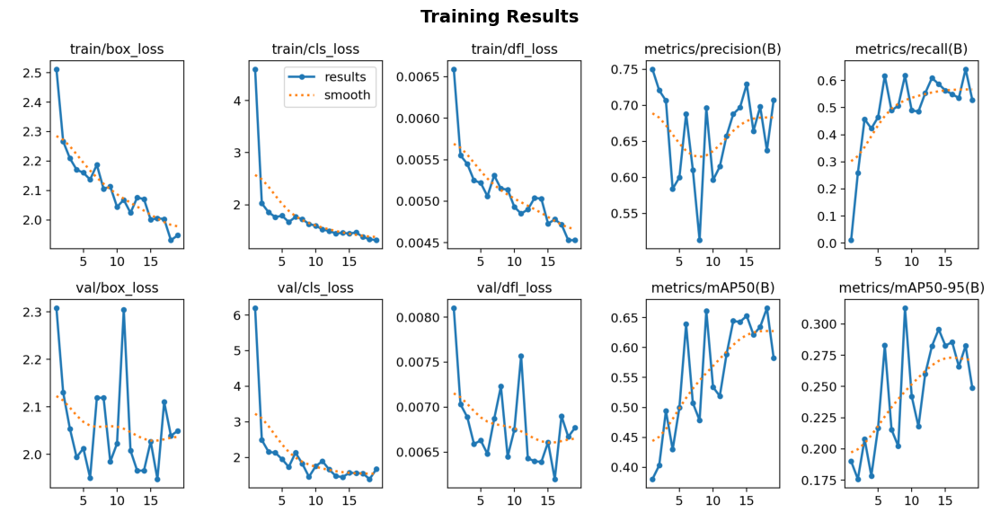

Metrics on 'val':
  mAP50:     0.6597
  mAP50-95:  0.3141
  Precision: 0.6935
  Recall:    0.6178
  F1:        0.6534
Metrics on 'test':
  mAP50:     0.5990
  mAP50-95:  0.2595
  Precision: 0.5919
  Recall:    0.6297
  F1:        0.6102


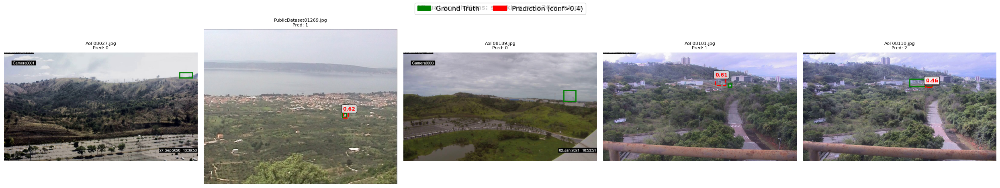


OWN MODEL: YOLOv26s_smoke_micro
Evaluating: smoking_yolo26s_micro
Weights: runs/detect/smoke_boxes_micro_s/smoking_yolo26s_micro/weights/best.pt
Dataset: smoke_yolo_dataset_micro


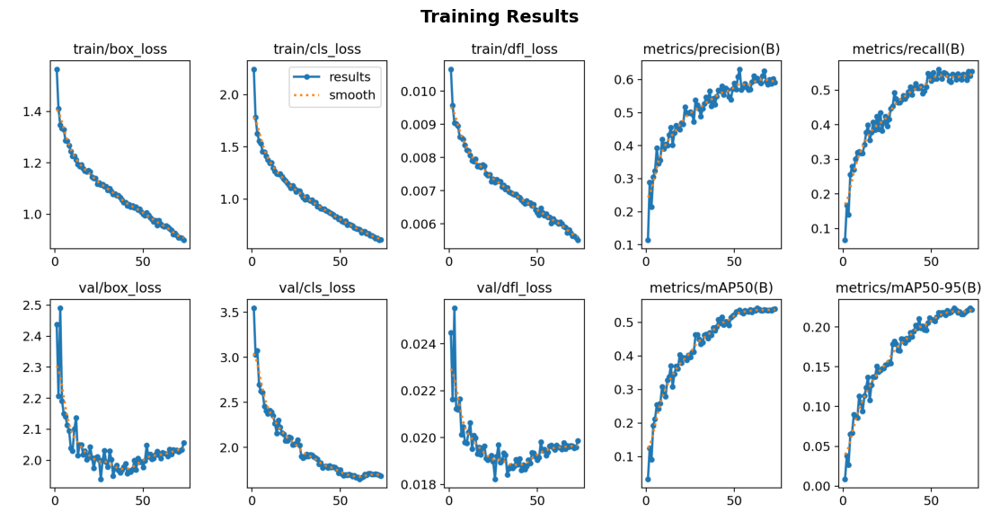

Metrics on 'val':
  mAP50:     0.7453
  mAP50-95:  0.3751
  Precision: 0.7780
  Recall:    0.6844
  F1:        0.7282
Metrics on 'test':
  mAP50:     0.7331
  mAP50-95:  0.3469
  Precision: 0.7395
  Recall:    0.7237
  F1:        0.7315


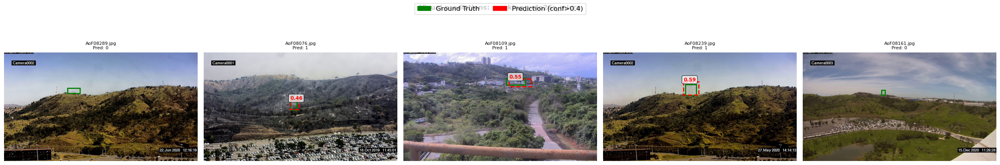


OWN MODEL: YOLOv26s_smoke_small
Evaluating: smoking_yolo26s
Weights: runs/detect/smoke_boxes_small_s/smoking_yolo26s/weights/best.pt
Dataset: smoke_yolo_dataset


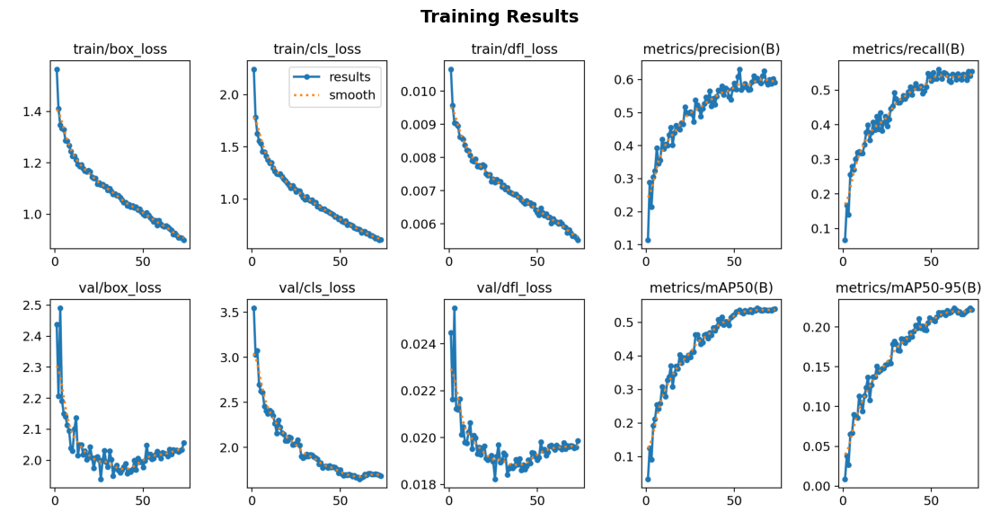

Metrics on 'val':
  mAP50:     0.4807
  mAP50-95:  0.1829
  Precision: 0.5542
  Recall:    0.4935
  F1:        0.5221
Metrics on 'test':
  mAP50:     0.7180
  mAP50-95:  0.3260
  Precision: 0.7285
  Recall:    0.6449
  F1:        0.6842


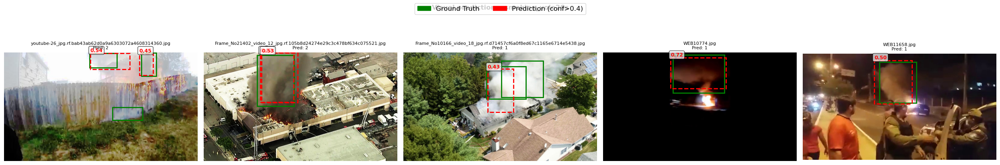


OWN MODEL: YOLOv26m_smoke_small
Evaluating: smoking_yolo26m
Weights: runs/detect/smoke_boxes_small_m/smoking_yolo26m/weights/best.pt
Dataset: smoke_yolo_dataset


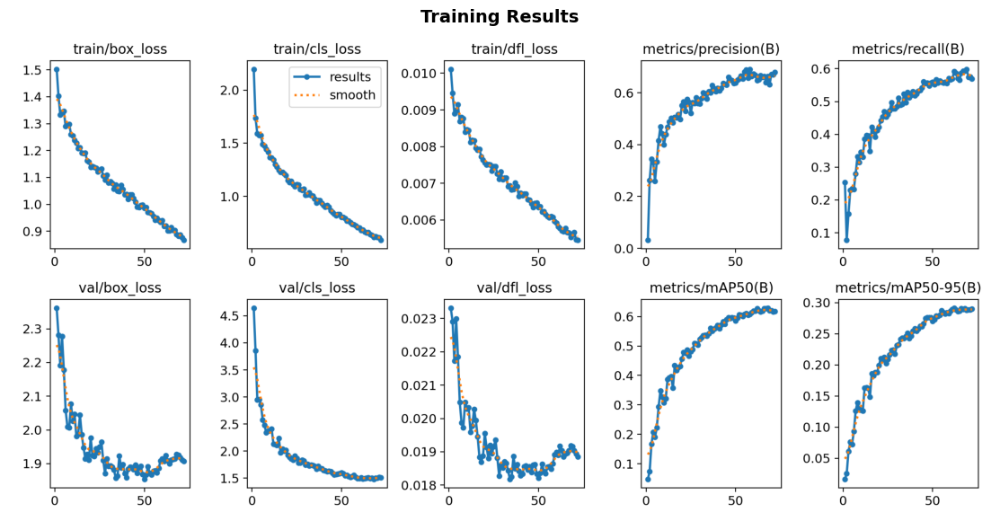

Metrics on 'val':
  mAP50:     0.4870
  mAP50-95:  0.1870
  Precision: 0.5443
  Recall:    0.5156
  F1:        0.5295
Metrics on 'test':
  mAP50:     0.7290
  mAP50-95:  0.3391
  Precision: 0.7375
  Recall:    0.6441
  F1:        0.6876


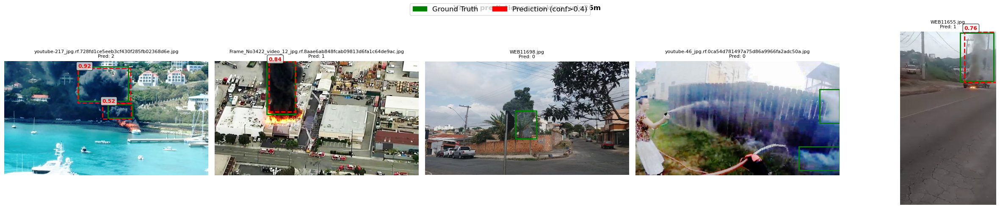

In [83]:
logging.getLogger('ultralytics').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')

own_results = []

for exp in OWN_EXPERIMENTS:
    print(f"\n{'='*60}")
    print(f"OWN MODEL: {exp['name']}")
    try:
        summary = evaluate_experiment(
            experiment_dir=exp['experiment_dir'],
            dataset_path=exp['dataset_path'],
            conf=CONF,
            n_visual_samples=N_VISUAL_SAMPLES,
            device=DEVICE,
        )
        for split, metrics in summary.items():
            own_results.append({
                'model': exp['name'],
                'type': 'own',
                'dataset': str(exp['dataset_path']),
                'split': split,
                **metrics,
            })
    except Exception as e:
        print(f'ERROR: {e}')

In [84]:
probe_dir = SMALL_DATASET_DIR / 'test' / 'images'
if not probe_dir.exists():
    probe_dir = SMALL_DATASET_DIR / 'val' / 'images'
all_probe = list(probe_dir.iterdir())
probe_images = random.sample(all_probe, min(3, len(all_probe)))
print(f'Probe images: {[p.name for p in probe_images]}')

Probe images: ['AoF08037.jpg', 'youtube-83_jpg.rf.d88af8ff5e55d506faf530b5fde0f79f.jpg', 'AoF08335.jpg']



Model: TommyNgx_yolov10_fire_smoke
Classes: 0:Fire, 1:Smoke


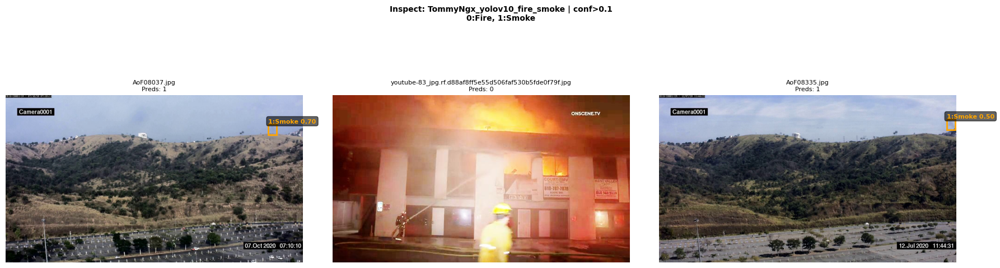

Resolved smoke class ids: [1] from names ['smoke', 'Smoke']

Model: leeyunjai_yolo11s_fire_smoke
Classes: 0:Fire, 1:Smoke


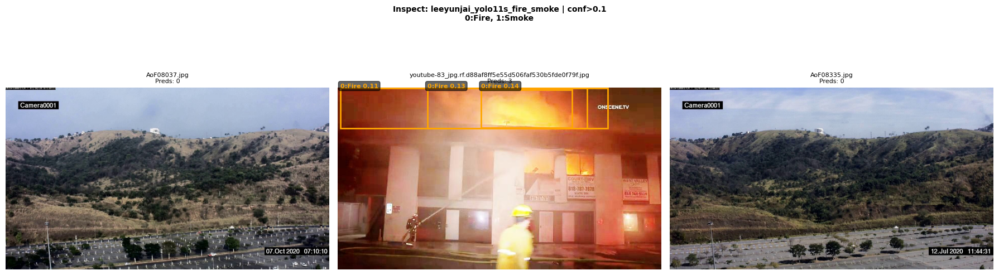

Resolved smoke class ids: [1] from names ['smoke']

Model: leeyunjai_yolo11x_fire_smoke
Classes: 0:Fire, 1:Smoke


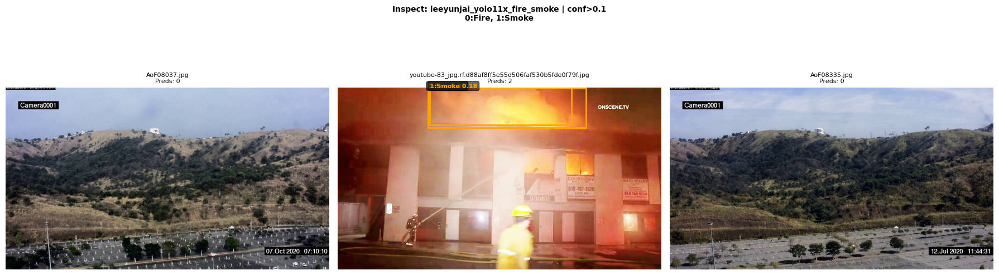

Resolved smoke class ids: [1] from names ['smoke']


In [85]:
os_models_loaded = {}
os_class_ids = {}

for cfg in OPENSOURCE_MODELS:
    model, names = inspect_model_classes(cfg, probe_images, conf=0.1, device=DEVICE)
    if model is not None:
        os_models_loaded[cfg['name']] = model
        os_class_ids[cfg['name']] = resolve_smoke_class_ids(names, cfg['smoking_class_names'])

In [86]:
os_results = []

for cfg in OPENSOURCE_MODELS:
    model = os_models_loaded.get(cfg['name'])
    if model is None:
        print(f'Model {cfg["name"]} not loaded, skipping')
        continue

    class_ids = os_class_ids.get(cfg['name'], [])
    if not class_ids:
        print(f'No smoke class ids resolved for {cfg["name"]}, skipping')
        continue

    for dataset_path in [SMALL_DATASET_DIR, MICRO_DATASET_DIR]:
        for split in ['val', 'test']:
            print(f"\n{'='*60}")
            print(f"OPENSOURCE: {cfg['name']} | dataset: {dataset_path.name} | split: {split}")

            metrics = compute_metrics_custom(
                model=model,
                dataset_path=dataset_path,
                split=split,
                smoking_class_ids=class_ids,
                conf=CONF,
                iou_thresh=0.5,
                device=DEVICE,
            )
            if metrics is None:
                print(f'Split {split} not found in {dataset_path}, skipping')
                continue

            print(f'  mAP50:     {metrics["mAP50"]:.4f}')
            print(f'  Precision: {metrics["precision"]:.4f}')
            print(f'  Recall:    {metrics["recall"]:.4f}')
            print(f'  F1:        {metrics["f1"]:.4f}')

            os_results.append({
                'model': cfg['name'],
                'type': 'opensource',
                'dataset': dataset_path.name,
                'split': split,
                **metrics,
            })


OPENSOURCE: TommyNgx_yolov10_fire_smoke | dataset: smoke_yolo_dataset | split: val
  mAP50:     0.0329
  Precision: 0.3165
  Recall:    0.1186
  F1:        0.1726

OPENSOURCE: TommyNgx_yolov10_fire_smoke | dataset: smoke_yolo_dataset | split: test
  mAP50:     0.3934
  Precision: 0.7359
  Recall:    0.4718
  F1:        0.5749

OPENSOURCE: TommyNgx_yolov10_fire_smoke | dataset: smoke_yolo_dataset_micro | split: val
  mAP50:     0.4987
  Precision: 0.7656
  Recall:    0.5674
  F1:        0.6517

OPENSOURCE: TommyNgx_yolov10_fire_smoke | dataset: smoke_yolo_dataset_micro | split: test
  mAP50:     0.6430
  Precision: 0.7620
  Recall:    0.6319
  F1:        0.6909

OPENSOURCE: leeyunjai_yolo11s_fire_smoke | dataset: smoke_yolo_dataset | split: val
  mAP50:     0.0121
  Precision: 0.2337
  Recall:    0.0608
  F1:        0.0965

OPENSOURCE: leeyunjai_yolo11s_fire_smoke | dataset: smoke_yolo_dataset | split: test
  mAP50:     0.1601
  Precision: 0.6460
  Recall:    0.2251
  F1:        0.3339

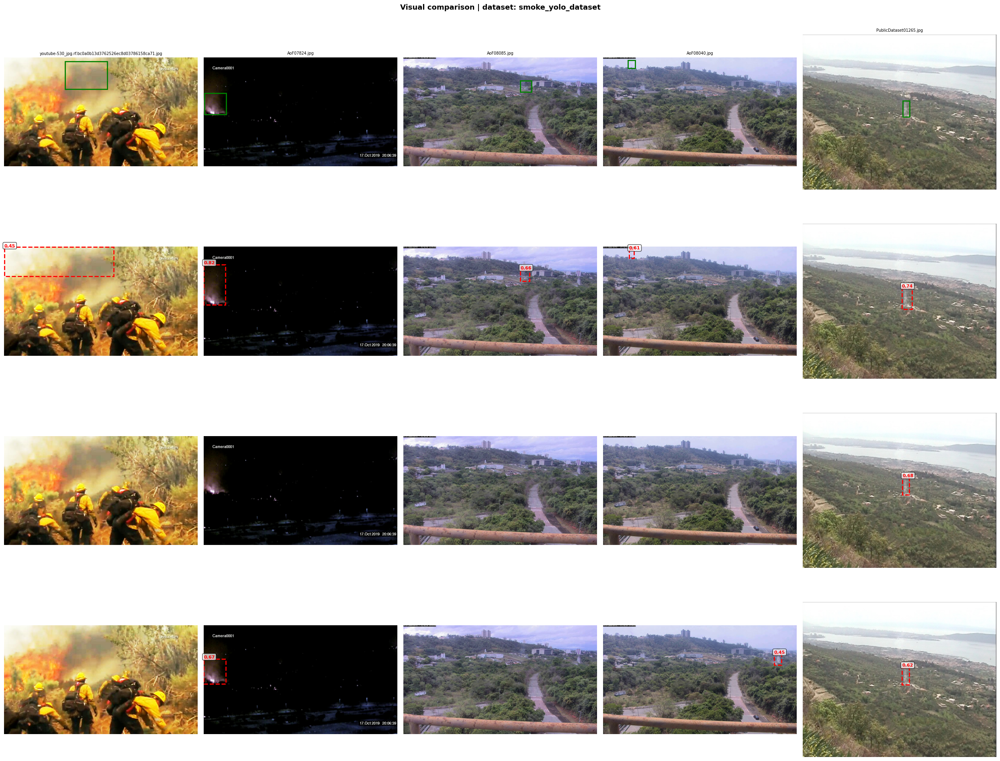

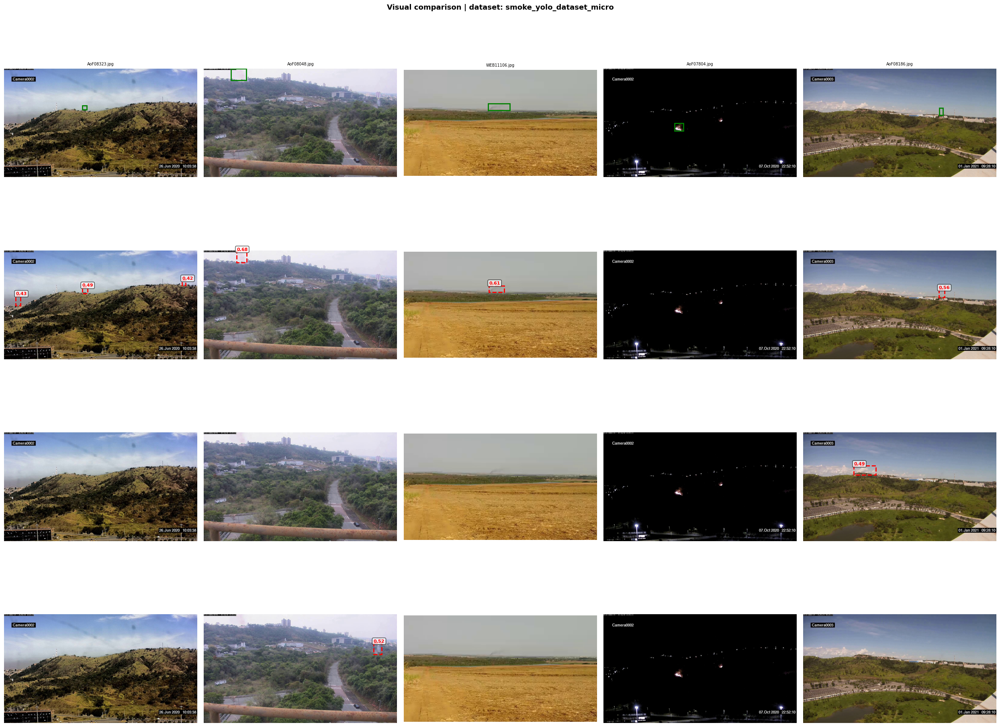

In [87]:
for dataset_path in [SMALL_DATASET_DIR, MICRO_DATASET_DIR]:
    test_images_dir = dataset_path / 'test' / 'images'
    test_labels_dir = dataset_path / 'test' / 'labels'
    if not test_images_dir.exists():
        test_images_dir = dataset_path / 'val' / 'images'
        test_labels_dir = dataset_path / 'val' / 'labels'
    if not test_images_dir.exists():
        continue

    all_imgs = list(test_images_dir.iterdir())
    sample_imgs = random.sample(all_imgs, min(N_VISUAL_SAMPLES, len(all_imgs)))

    os_model_list = [
        (cfg['name'], os_models_loaded[cfg['name']], os_class_ids[cfg['name']])
        for cfg in OPENSOURCE_MODELS
        if cfg['name'] in os_models_loaded
    ]

    n_rows = 1 + len(os_model_list)
    n_cols = len(sample_imgs)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
    if n_rows == 1:
        axes = [axes]
    if n_cols == 1:
        axes = [[ax] for ax in axes]

    for col_idx, img_path in enumerate(sample_imgs):
        img_cv = cv2.imread(str(img_path))
        img_rgb = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]
        lbl_path = test_labels_dir / (img_path.stem + '.txt')

        ax = axes[0][col_idx]
        ax.imshow(img_rgb)
        if lbl_path.exists():
            with open(lbl_path, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        _, xc, yc, bw, bh = map(float, parts[:5])
                        x1 = int((xc - bw / 2) * w)
                        y1 = int((yc - bh / 2) * h)
                        rect = patches.Rectangle(
                            (x1, y1), int(bw * w), int(bh * h),
                            linewidth=2, edgecolor='green', facecolor='none'
                        )
                        ax.add_patch(rect)
        if col_idx == 0:
            ax.set_ylabel('Ground Truth', fontsize=9, fontweight='bold')
        ax.set_title(img_path.name, fontsize=7)
        ax.axis('off')

        for row_idx, (model_name, model, class_ids) in enumerate(os_model_list):
            ax = axes[row_idx + 1][col_idx]
            ax.imshow(img_rgb)
            results = model.predict(str(img_path), conf=CONF, device=DEVICE, verbose=False)
            if len(results[0].boxes) > 0:
                cls_ids = results[0].boxes.cls.cpu().numpy().astype(int)
                boxes = results[0].boxes.xyxy.cpu().numpy()
                scores = results[0].boxes.conf.cpu().numpy()
                for box, score, cls_id in zip(boxes, scores, cls_ids):
                    if cls_id not in class_ids:
                        continue
                    x1, y1, x2, y2 = box
                    rect = patches.Rectangle(
                        (x1, y1), x2 - x1, y2 - y1,
                        linewidth=2, edgecolor='red', facecolor='none', linestyle='--'
                    )
                    ax.add_patch(rect)
                    ax.text(
                        x1, max(y1 - 5, 0), f'{score:.2f}',
                        color='red', fontsize=8, weight='bold',
                        bbox=dict(boxstyle='round', facecolor='white', alpha=0.7)
                    )
            if col_idx == 0:
                ax.set_ylabel(model_name, fontsize=9, fontweight='bold')
            ax.axis('off')

    fig.suptitle(f'Visual comparison | dataset: {dataset_path.name}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'visual_comparison_{dataset_path.name}.png', dpi=120, bbox_inches='tight')
    plt.show()

In [88]:
all_results = own_results + os_results
df = pd.DataFrame(all_results)
df['mAP50'] = df['mAP50'].round(4)
df['precision'] = df['precision'].round(4)
df['recall'] = df['recall'].round(4)
df['f1'] = df['f1'].round(4)
if 'mAP50-95' in df.columns:
    df['mAP50-95'] = df['mAP50-95'].round(4)

df.to_csv(OUTPUT_DIR / 'smoke_comparison_results.csv', index=False)
print('Results saved to smoke_comparison_results.csv')
display(df)

Results saved to smoke_comparison_results.csv


,model,type,dataset,split,mAP50,mAP50-95,precision,recall,f1
0,YOLOv26m_smoke_micro,own,smoke_yolo_dataset_micro,val,0.6597,0.3141,0.6935,0.6178,0.6534
1,YOLOv26m_smoke_micro,own,smoke_yolo_dataset_micro,test,0.5990,0.2595,0.5919,0.6297,0.6102
2,YOLOv26s_smoke_micro,own,smoke_yolo_dataset_micro,val,0.7453,0.3751,0.7780,0.6844,0.7282
3,YOLOv26s_smoke_micro,own,smoke_yolo_dataset_micro,test,0.7331,0.3469,0.7395,0.7237,0.7315
4,YOLOv26s_smoke_small,own,smoke_yolo_dataset,val,0.4807,0.1829,0.5542,0.4935,0.5221
5,YOLOv26s_smoke_small,own,smoke_yolo_dataset,test,0.7180,0.3260,0.7285,0.6449,0.6842
6,YOLOv26m_smoke_small,own,smoke_yolo_dataset,val,0.4870,0.1870,0.5443,0.5156,0.5295
7,YOLOv26m_smoke_small,own,smoke_yolo_dataset,test,0.7290,0.3391,0.7375,0.6441,0.6876
8,TommyNgx_yolov10_fire_smoke,opensource,smoke_yolo_dataset,val,0.0329,NaN,0.3165,0.1186,0.1726
9,TommyNgx_yolov10_fire_smoke,opensource,smoke_yolo_dataset,test,0.3934,NaN,0.7359,0.4718,0.5749


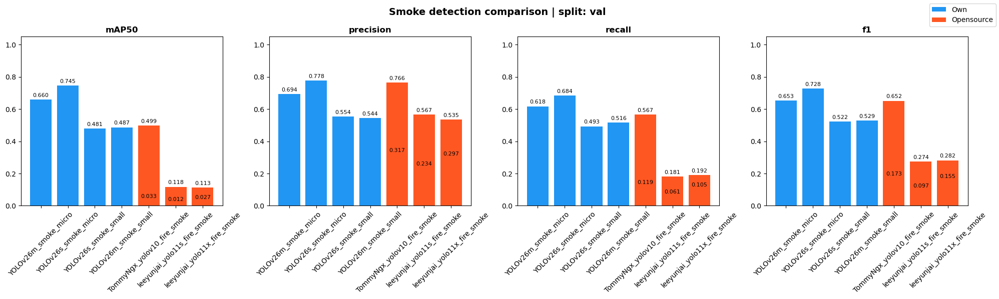

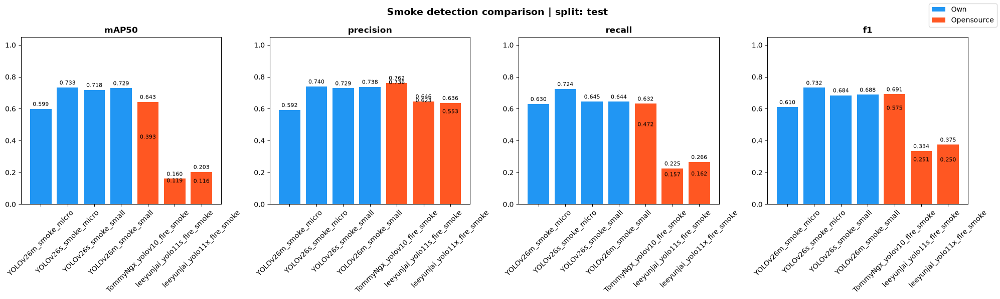

In [89]:
for split in ['val', 'test']:
    df_split = df[df['split'] == split].copy()
    if df_split.empty:
        continue

    metrics = ['mAP50', 'precision', 'recall', 'f1']
    available = [m for m in metrics if m in df_split.columns]
    n_metrics = len(available)

    fig, axes = plt.subplots(1, n_metrics, figsize=(5 * n_metrics, 6))
    if n_metrics == 1:
        axes = [axes]

    colors = ['#2196F3' if t == 'own' else '#FF5722' for t in df_split['type']]

    for ax, metric in zip(axes, available):
        bars = ax.bar(df_split['model'], df_split[metric], color=colors)
        ax.set_title(metric, fontsize=12, fontweight='bold')
        ax.set_ylim(0, 1.05)
        ax.tick_params(axis='x', rotation=45)
        for bar, val in zip(bars, df_split[metric]):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.01,
                f'{val:.3f}',
                ha='center', va='bottom', fontsize=8
            )

    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#2196F3', label='Own'),
        Patch(facecolor='#FF5722', label='Opensource'),
    ]
    fig.legend(handles=legend_elements, loc='upper right', fontsize=10)
    fig.suptitle(f'Smoke detection comparison | split: {split}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'comparison_barplot_{split}.png', dpi=150, bbox_inches='tight')
    plt.show()

In [90]:
model_k = YOLO(hf_hub_download('kittendev/YOLOv8m-smoke-detection', 'best.pt'))
images_dir = SMALL_DATASET_DIR / 'test' / 'images'
sample = list(images_dir.iterdir())[:10]
for img_path in sample:
    r = model_k.predict(str(img_path), conf=0.1, device=DEVICE, verbose=False)
    cls_ids = r[0].boxes.cls.cpu().numpy().astype(int).tolist() if len(r[0].boxes) else []
    print(f'{img_path.name}: {cls_ids}')

Frame_No1914_video_15_jpg.rf.955748aaf3d3b29c43a3d5ccb23d32ce.jpg: [0]
Frame_No3300_video_1_jpg.rf.ec174fcd7cfa319e9962fd16d171a6dd.jpg: [0]
PublicDataset01261.jpg: []
AoF08330.jpg: []
AoF08130.jpg: []
AoF08077.jpg: []
AoF08008.jpg: []
Frame_No21594_video_10_jpg.rf.d28b16b86ccc0cc5207d536702076244.jpg: [0]
PublicDataset01150.jpg: [0]
Frame_No3634_video_18_jpg.rf.fe88f99cc68777476cdcd78b525d6d8b.jpg: [0]


In [91]:
model_k = YOLO(hf_hub_download('kittendev/YOLOv8m-smoke-detection', 'best.pt'))
print(model_k.names)
print(resolve_smoke_class_ids(model_k.names, ['smoke']))

{0: 'smoke'}
Resolved smoke class ids: [0] from names ['smoke']
[0]
